# Image Spatter — guided ELA demo

In this controlled experiment, we paste a small badge into an image, recompress it as JPEG, and see how the pixel differences change. Open this notebook from the repository root in Jupyter and run the cells in order. This guided version writes to `outputs/v2_anlatimli/`. Python handles the analysis locally.

For the current copy-move, metadata, and noise experiments, open the [main notebook](Image_Spatter_Demo.ipynb) and see sections 10 and 11.


## Error Level Analysis

Error Level Analysis (ELA) compares an input image with a JPEG-recompressed copy. For each pixel, we take the absolute difference in each color channel and average the three values. Brighter pixels on the map have larger recompression differences. Edges, fine textures, and editing can all affect that map.


## 1. Import the tools

OpenCV loads images and encodes JPEGs. NumPy handles image arrays and statistics. Matplotlib draws the images and maps. Path objects keep the example files relative to the project.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter


## 2. Load the bundled image

Open the astronaut PNG from `data/` and prepare an output directory. OpenCV loads color channels in blue, green, red order, so the display cells convert them to RGB.


In [2]:
data_dir = Path("data")
output_dir = Path("outputs") / "v2_anlatimli"
output_dir.mkdir(parents=True, exist_ok=True)

source_img = cv2.imread(str(data_dir / "astronaut.png"))

if source_img is None:
    raise FileNotFoundError("Open the notebook from the repository root. data/astronaut.png was not found.")

print("Image shape:", source_img.shape)


Image shape: (512, 512, 3)


The image shape `(512, 512, 3)` gives the number of rows, columns, and color channels.


## 3. Prepare a controlled edit

Start by creating a JPEG at quality 75. Both the control and the edited image start from this shared background. The edited image receives a patch from the original PNG.


In [3]:
base_path = output_dir / "base_q75.jpg"

cv2.imwrite(str(base_path), source_img, [cv2.IMWRITE_JPEG_QUALITY, 75])
base_img = cv2.imread(str(base_path))


### 3.2. Copy and paste a patch

Copy rows 340–419 and columns 130–209 from the PNG, then paste the 80 × 80 badge near the upper-right corner. The slice endpoints are exclusive.


In [4]:
patch = source_img[340:420, 130:210].copy()

edited_img = base_img.copy()
edited_img[40:120, 390:470] = patch


### 3.3. Save both images at the same final quality

Save the control and the edited image as separate quality-95 JPEGs and load them again. This keeps the final encoding setting comparable.


In [5]:
original_path = output_dir / "control.jpg"
edited_path = output_dir / "edited.jpg"

cv2.imwrite(str(original_path), base_img, [cv2.IMWRITE_JPEG_QUALITY, 95])
cv2.imwrite(str(edited_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, 95])

original_img = cv2.imread(str(original_path))
edited_img = cv2.imread(str(edited_path))


### 3.4. Mark the known patch

The white mask records where we pasted the badge. We use it to compare the same region in both images.


In [6]:
known_mask = np.zeros(edited_img.shape[:2], dtype=np.uint8)
known_mask[40:120, 390:470] = 255

cv2.imwrite(str(output_dir / "known_mask.png"), known_mask)


True

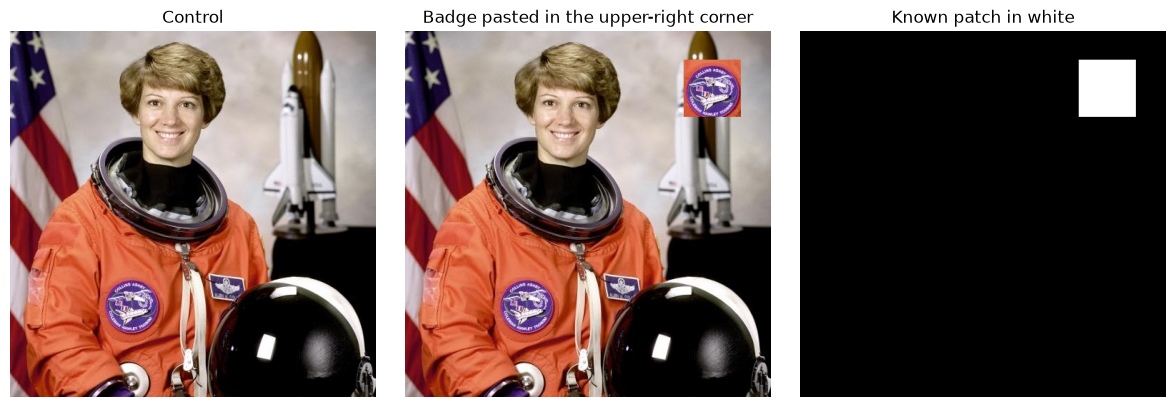

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Control")
plt.axis(False)

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Badge pasted in the upper-right corner")
plt.axis(False)

plt.subplot(1, 3, 3)
plt.imshow(known_mask, cmap="gray", vmin=0, vmax=255)
plt.title("Known patch in white")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "controlled_edit.png")
plt.show()


## 4. Work through the ELA calculation

Encode the edited image at JPEG quality 90 and reload it. Saving an intermediate file makes the first recompression step visible.


In [8]:
jpeg_quality = 90
recompressed_path = output_dir / "recompressed.jpg"

cv2.imwrite(str(recompressed_path), edited_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_img = cv2.imread(str(recompressed_path))


### 4.2. Compare the images pixel by pixel

`cv2.absdiff` takes the absolute difference separately for each color channel. Its output has the same shape as the source.


In [9]:
difference_img = cv2.absdiff(edited_img, recompressed_img)

print("Difference image shape:", difference_img.shape)


Difference image shape: (512, 512, 3)


### 4.3. Average the three color channels

`mean(axis=2)` reduces the color dimension and leaves one difference value per pixel. These are raw differences on the 0–255 channel scale.


In [10]:
edited_ela = difference_img.mean(axis=2)

print("ELA map shape:", edited_ela.shape)
print("Mean image difference:", round(edited_ela.mean(), 3))


ELA map shape: (512, 512)
Mean image difference: 0.801


### 4.4. Repeat the calculation on the control

Use the same recompression quality and difference calculation for the image without the pasted badge.


In [11]:
cv2.imwrite(str(recompressed_path), original_img, [cv2.IMWRITE_JPEG_QUALITY, jpeg_quality])
recompressed_original = cv2.imread(str(recompressed_path))

original_difference = cv2.absdiff(original_img, recompressed_original)
original_ela = original_difference.mean(axis=2)


## 5. Compare the results

Read the input images alongside their ELA maps. Both maps use the same display range of 0–20. Values outside that range are clipped for display, while measurements use the raw values.


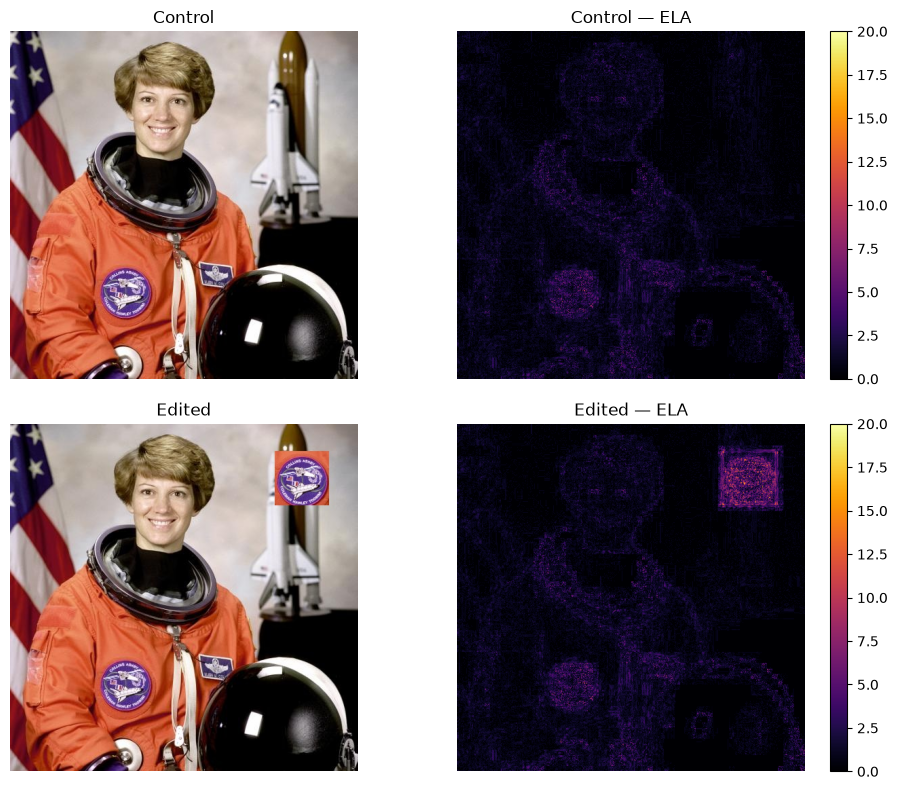

In [12]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
plt.title("Control")
plt.axis(False)

plt.subplot(2, 2, 2)
plt.imshow(original_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Control — ELA")
plt.axis(False)

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.title("Edited")
plt.axis(False)

plt.subplot(2, 2, 4)
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20)
plt.colorbar()
plt.title("Edited — ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_comparison.png")
plt.show()


### Overlay the map

Matplotlib's `alpha` parameter controls how much of the map and the underlying image you see. The location of a bright area is easier to inspect with the overlay.


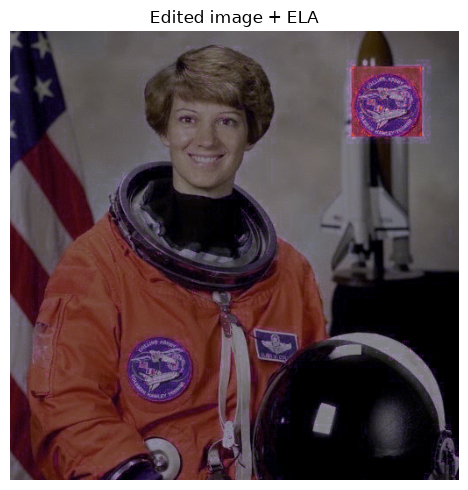

In [13]:
plt.figure(figsize=(5, 5))

plt.imshow(cv2.cvtColor(edited_img, cv2.COLOR_BGR2RGB))
plt.imshow(edited_ela, cmap="inferno", vmin=0, vmax=20, alpha=0.5)
plt.title("Edited image + ELA")
plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "ela_overlay.png")
plt.show()


### Measure the same region

Find the mean ELA value inside rows 40–119 and columns 390–469. This compares the same region in the control and the edited image.


In [14]:
original_region = original_ela[40:120, 390:470]
edited_region = edited_ela[40:120, 390:470]

print("Mean control difference in the region:", round(original_region.mean(), 3))
print("Mean edited difference in the region:", round(edited_region.mean(), 3))

print("Both measurements are mean pixel differences in the same region.")


Mean control difference in the region: 0.556
Mean edited difference in the region: 4.475
Both measurements are mean pixel differences in the same region.


## 6. Use the shared ELA engine

Call `calculate_ela(image, quality)` from `image_spatter.ela`. It recompresses the image in memory and returns the mean absolute difference across the three channels for each pixel. The same engine supports the desktop application and the academic evaluation. The following assertion compares the shared result against the manual calculation pixel by pixel.


In [15]:
from image_spatter.ela import calculate_ela

np.testing.assert_array_equal(calculate_ela(edited_img, jpeg_quality), edited_ela)


### Measure runtime

Subtract the start time from the end time and multiply by 1,000 to get milliseconds. This measures the in-memory JPEG round trip and difference calculation.


In [16]:
start_time = perf_counter()

test_ela = calculate_ela(edited_img, 90)

elapsed_ms = (perf_counter() - start_time) * 1000
print("ELA runtime (ms):", round(elapsed_ms, 2))


ELA runtime (ms): 5.82


## 7. Compare JPEG qualities

Try qualities 5, 10, 20, 40, 60, 80, 90, and 95. Every run starts from the same control or edited input. Lower qualities can produce larger differences across the image, including in areas untouched by the edit.


In [17]:
qualities = [5, 10, 20, 40, 60, 80, 90, 95]
original_maps = []
edited_maps = []
quality_results = []

for quality in qualities:
    start_time = perf_counter()
    original_map = calculate_ela(original_img, quality)
    original_time = (perf_counter() - start_time) * 1000

    start_time = perf_counter()
    edited_map = calculate_ela(edited_img, quality)
    edited_time = (perf_counter() - start_time) * 1000

    original_mean = original_map[40:120, 390:470].mean()
    edited_mean = edited_map[40:120, 390:470].mean()

    original_maps.append(original_map)
    edited_maps.append(edited_map)
    quality_results.append([quality, original_mean, edited_mean, original_time, edited_time])

    print("JPEG quality:", quality)
    print("  Mean control difference in the region:", round(original_mean, 3))
    print("  Mean edited difference in the region:", round(edited_mean, 3))


JPEG quality: 5
  Mean control difference in the region: 9.712
  Mean edited difference in the region: 24.351
JPEG quality: 10
  Mean control difference in the region: 6.567
  Mean edited difference in the region: 18.862
JPEG quality: 20
  Mean control difference in the region: 4.307
  Mean edited difference in the region: 15.044
JPEG quality: 40
  Mean control difference in the region: 2.89
  Mean edited difference in the region: 11.598
JPEG quality: 60
  Mean control difference in the region: 2.015
  Mean edited difference in the region: 9.476
JPEG quality: 80
  Mean control difference in the region: 0.844
  Mean edited difference in the region: 6.625
JPEG quality: 90
  Mean control difference in the region: 0.556
  Mean edited difference in the region: 4.475
JPEG quality: 95
  Mean control difference in the region: 0.273
  Mean edited difference in the region: 2.046


### Compare all quality settings

The upper maps are from the control and the lower maps are from the edited image. Every map uses the same 0–20 color scale.


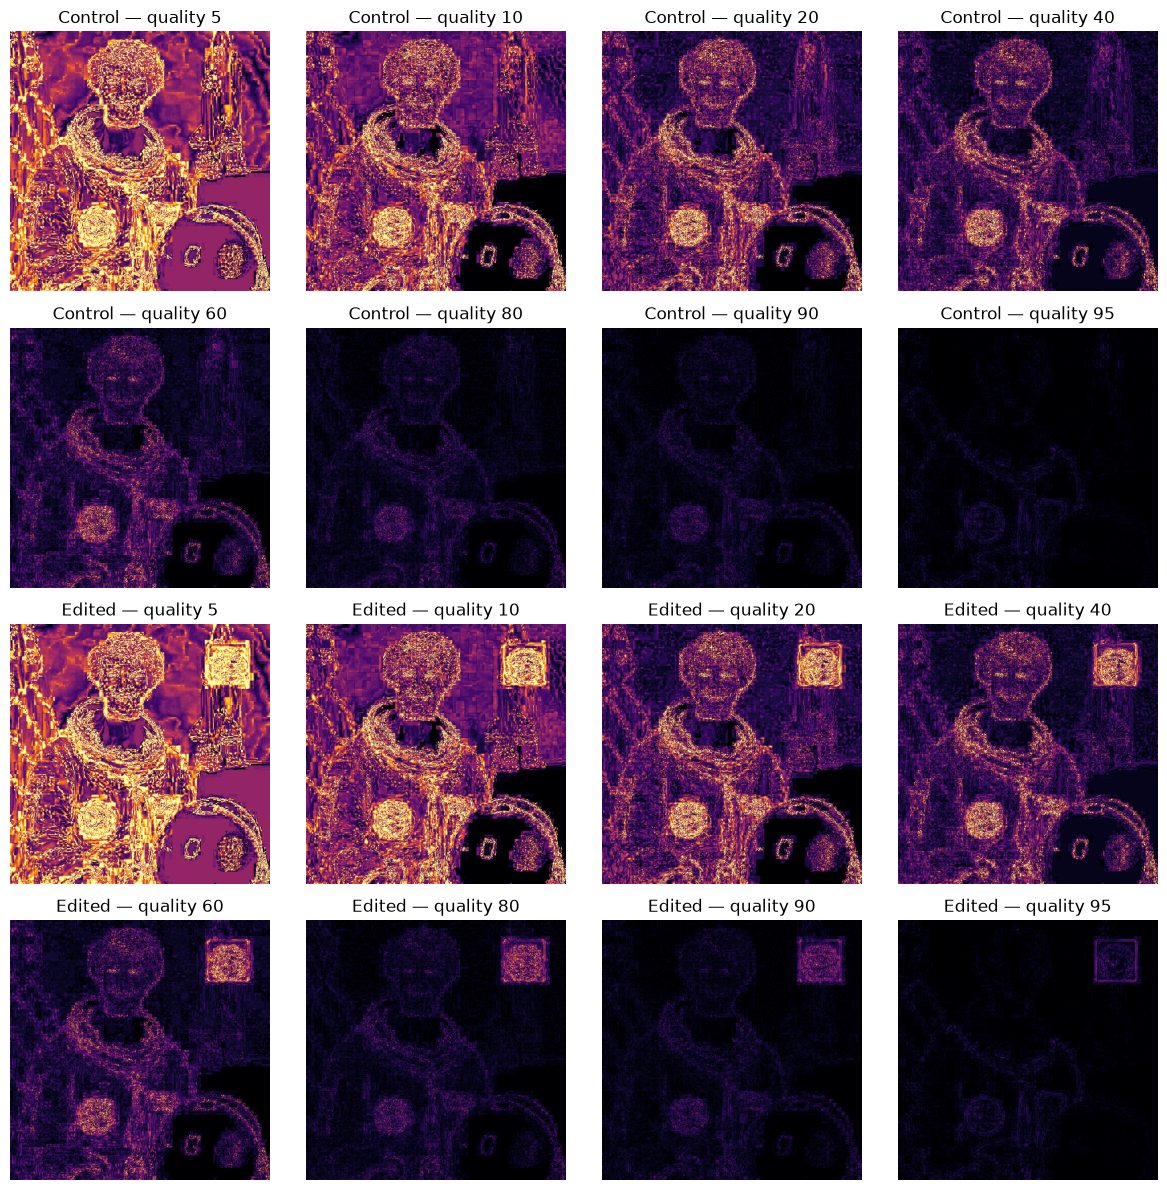

In [18]:
# Each row has at most 4 maps
columns = min(4, len(qualities))
rows = (len(qualities) + columns - 1) // columns
control_slots = rows * columns

plt.figure(figsize=(3 * columns, 6 * rows))

for i in range(len(qualities)):
    # Upper half: control image.
    plt.subplot(2 * rows, columns, i + 1)
    plt.imshow(original_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Control — quality {qualities[i]}")
    plt.axis(False)

    # Lower half: edited image.
    plt.subplot(2 * rows, columns, control_slots + i + 1)
    plt.imshow(edited_maps[i], cmap="inferno", vmin=0, vmax=20)
    plt.title(f"Edited — quality {qualities[i]}")
    plt.axis(False)

plt.tight_layout()
plt.savefig(output_dir / "quality_comparison.png")
plt.show()


### Save the measurements

The CSV records the quality, the control and edited means in the known patch region, and the two analysis times.


In [19]:
np.savetxt(
    output_dir / "quality_comparison.csv",
    quality_results,
    delimiter=",",
    header="jpeg_quality,control_region_mean,edited_region_mean,control_time_ms,edited_time_ms",
    comments="",
    fmt="%.3f"
)


## What the example shows

The known patch and normal features such as edges and texture can both produce recompression differences. Changing JPEG quality changes what stands out. This controlled comparison illustrates the method and its limits rather than measuring general detection accuracy.


## 8. Custom image

This section can run without the controlled experiment. Set the local image path, run the analysis, compare qualities, and optionally inspect a region or export the results.


In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter
from tempfile import mkdtemp
from PIL import Image, ImageOps


### Settings

Set `custom_image_path` to a relative or absolute path. Use `None` to skip the custom image. `custom_quality` selects the analysis quality, `custom_display_max` sets the color scale, and `custom_overlay_alpha` controls the overlay. Set `custom_roi` to `(x, y, width, height)` for a crop, or leave it unset.


In [21]:
custom_image_path = "data/astronaut.png"
custom_quality = 80

custom_display_max = 20
custom_overlay_alpha = 0.5
custom_qualities = [5, 10, 20, 40, 60, 80, 90, 95]
custom_roi = None  # Optional region: (x, y, width, height)

custom_save_outputs = True
custom_output_root = Path("outputs") / "v2_anlatimli" / "custom"


### Load the image

Pillow reads the image format and EXIF orientation. Transparent areas are placed on a white background and the input is converted to 8-bit BGR for OpenCV.


In [22]:
# Reset results
custom_img = None
custom_ela = None
custom_figure = None
custom_quality_figure = None
custom_roi_figure = None
custom_quality_rows = []
custom_roi_row = []

if custom_image_path is None:
    print("No image selected. Set custom_image_path.")
else:
    custom_path = Path(custom_image_path).expanduser()
    if not custom_path.is_file():
        raise FileNotFoundError("Image not found. Check the path.")

    with Image.open(custom_path) as image_file:
        custom_format = image_file.format
        oriented_img = ImageOps.exif_transpose(image_file)

        if oriented_img.mode not in ("1", "L", "LA", "P", "RGB", "RGBA", "CMYK", "YCbCr"):
            raise ValueError("Use an 8-bit image.")

        has_alpha = "A" in oriented_img.getbands() or "transparency" in image_file.info
        if has_alpha:
            rgba_img = oriented_img.convert("RGBA")
            white_background = Image.new("RGBA", rgba_img.size, "white")
            oriented_img = Image.alpha_composite(white_background, rgba_img)
            print("Transparent areas were placed on a white background.")

        custom_rgb = np.array(oriented_img.convert("RGB"))

    custom_img = cv2.cvtColor(custom_rgb, cv2.COLOR_RGB2BGR)
    print("File:", custom_path.name)
    print("Format:", custom_format)
    print("Size (height, width, channels):", custom_img.shape)

    if custom_format != "JPEG":
        print("The map shows differences from conversion to JPEG.")


File: astronaut.png
Format: PNG
Size (height, width, channels): (512, 512, 3)
The map shows differences from conversion to JPEG.


### Import the shared engine

The engine creates and decodes a JPEG in memory, computes absolute differences, and averages the three channels. The resulting map contains raw pixel differences.


In [23]:
from image_spatter.ela import calculate_ela as calculate_custom_ela


### Run the analysis

Report the overall mean, the 95th percentile, and analysis time. Loading the input and drawing or exporting the figures are outside the timed step.


In [24]:
if custom_img is not None:
    if not np.isfinite(custom_display_max) or custom_display_max <= 0:
        raise ValueError("Display maximum must be positive.")
    if not 0 <= custom_overlay_alpha <= 1:
        raise ValueError("Overlay opacity must be between 0 and 1.")

    start_time = perf_counter()
    custom_ela = calculate_custom_ela(custom_img, custom_quality)
    custom_elapsed_ms = (perf_counter() - start_time) * 1000

    print("JPEG quality:", custom_quality)
    print("Mean error:", round(custom_ela.mean(), 3))
    print("95th percentile:", round(np.percentile(custom_ela, 95), 3))
    print("Analysis time (ms):", round(custom_elapsed_ms, 2))


JPEG quality: 80
Mean error: 2.948
95th percentile: 8.667
Analysis time (ms): 4.99


### Input, ELA, and overlay

Inspect the full input and the map together. The overlay blends them using the selected opacity. Display clipping affects color only.


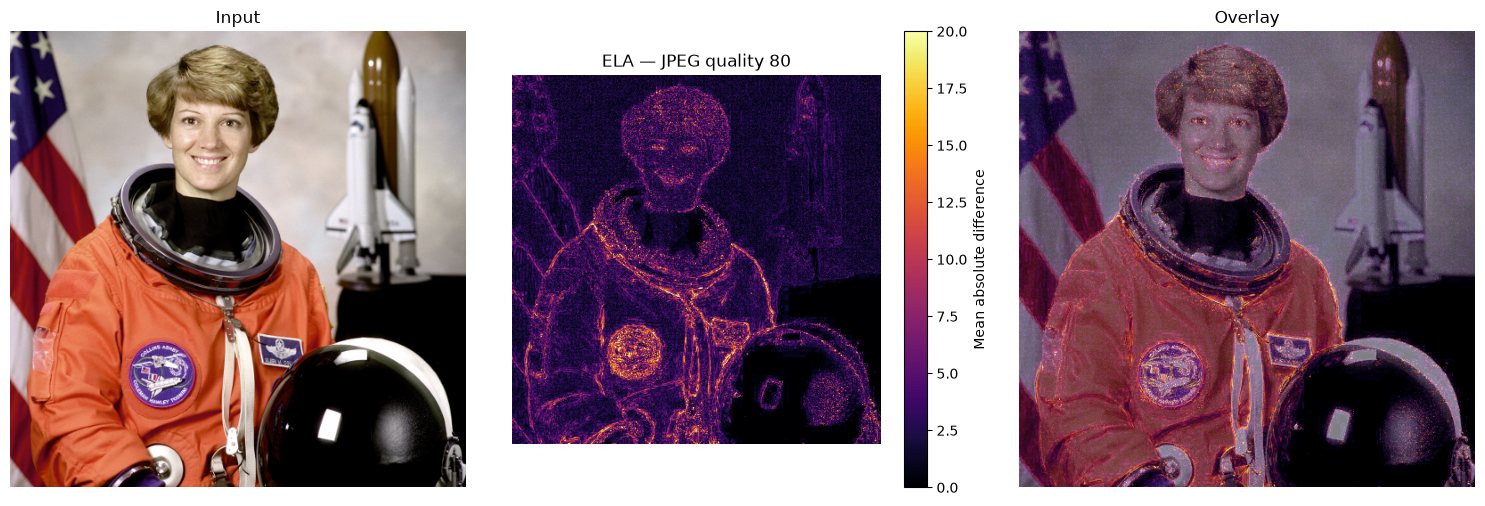

In [25]:
if custom_ela is not None:
    custom_figure = plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(custom_rgb)
    plt.title("Input")
    plt.axis(False)

    plt.subplot(1, 3, 2)
    plt.imshow(custom_ela, cmap="inferno", vmin=0, vmax=custom_display_max)
    plt.colorbar(label="Mean absolute difference")
    plt.title(f"ELA — JPEG quality {custom_quality}")
    plt.axis(False)

    plt.subplot(1, 3, 3)
    plt.imshow(custom_rgb)
    plt.imshow(custom_ela, cmap="inferno", vmin=0, vmax=custom_display_max,
               alpha=custom_overlay_alpha)
    plt.title("Overlay")
    plt.axis(False)

    plt.tight_layout()
    plt.show()


### Compare the same input at several qualities

Reuse the input image and color scale for each run. Report mean and P95 differences separately from analysis time.


Q=5: mean=11.413, P95=28.333, time=4.58 ms
Q=10: mean=7.734, P95=21.000, time=5.05 ms
Q=20: mean=5.481, P95=16.333, time=5.21 ms
Q=40: mean=4.333, P95=13.000, time=5.06 ms
Q=60: mean=3.666, P95=11.000, time=4.86 ms
Q=80: mean=2.948, P95=8.667, time=5.12 ms
Q=90: mean=2.371, P95=6.333, time=5.49 ms
Q=95: mean=1.950, P95=5.000, time=5.66 ms


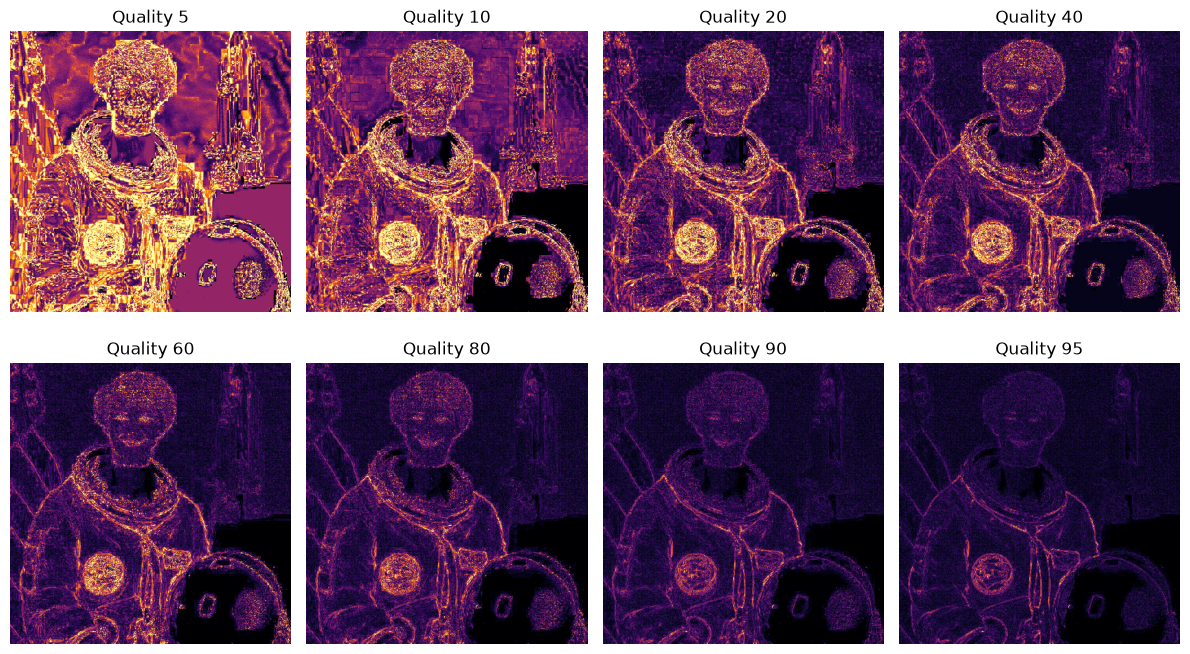

In [26]:
custom_quality_rows = []
custom_quality_figure = None

if custom_ela is not None:
    if not custom_qualities:
        raise ValueError("Enter at least one quality setting.")

    columns = min(4, len(custom_qualities))
    rows = (len(custom_qualities) + columns - 1) // columns
    custom_quality_figure = plt.figure(figsize=(3 * columns, 3.5 * rows))

    for i in range(len(custom_qualities)):
        quality = custom_qualities[i]
        start_time = perf_counter()
        quality_map = calculate_custom_ela(custom_img, quality)
        elapsed_ms = (perf_counter() - start_time) * 1000

        mean_error = float(quality_map.mean())
        p95_error = float(np.percentile(quality_map, 95))
        custom_quality_rows.append([quality, mean_error, p95_error, elapsed_ms])

        plt.subplot(rows, columns, i + 1)
        plt.imshow(quality_map, cmap="inferno", vmin=0, vmax=custom_display_max)
        plt.title(f"Quality {quality}")
        plt.axis(False)
        print(f"Q={quality}: mean={mean_error:.3f}, P95={p95_error:.3f}, time={elapsed_ms:.2f} ms")

    plt.tight_layout()
    plt.show()


### Inspect a region of interest

Coordinates are measured from the upper-left corner of the image. The region is cropped from the full-image ELA map, so the JPEG encoding still uses the full input.


In [27]:
custom_roi_row = []
custom_roi_figure = None

if custom_ela is not None and custom_roi is not None:
    if not isinstance(custom_roi, (tuple, list)) or len(custom_roi) != 4:
        raise ValueError("Specify ROI as (x, y, width, height).")
    if not all(type(value) is int for value in custom_roi):
        raise ValueError("ROI coordinates must be integers.")

    x, y, width, height = custom_roi
    image_height, image_width = custom_img.shape[:2]
    if x < 0 or y < 0 or width <= 0 or height <= 0:
        raise ValueError("ROI origin must be nonnegative and dimensions must be positive.")
    if x + width > image_width or y + height > image_height:
        raise ValueError("ROI is outside the image.")

    roi_rgb = custom_rgb[y:y + height, x:x + width]
    roi_ela = custom_ela[y:y + height, x:x + width]
    custom_roi_row = [x, y, width, height, float(roi_ela.mean())]

    roi_preview = custom_rgb.copy()
    cv2.rectangle(roi_preview, (x, y), (x + width - 1, y + height - 1), (0, 255, 0), 2)
    custom_roi_figure = plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(roi_preview)
    plt.title("Selected region")
    plt.axis(False)

    plt.subplot(1, 3, 2)
    plt.imshow(roi_rgb)
    plt.title("Crop")
    plt.axis(False)

    plt.subplot(1, 3, 3)
    plt.imshow(roi_ela, cmap="inferno", vmin=0, vmax=custom_display_max)
    plt.colorbar()
    plt.title("ROI — ELA")
    plt.axis(False)

    plt.tight_layout()
    plt.show()
    print("ROI mean error:", round(roi_ela.mean(), 3))


### Export locally

Each run has a separate output directory. It includes the comparison PNG, heatmap, raw `ela_raw.npy` array, quality comparison and measurements, and summary. If a region is selected, the export also includes the region view and CSV. Set `custom_save_outputs = False` to skip exporting.


In [28]:
if custom_ela is not None and custom_save_outputs:
    image_output_dir = custom_output_root / custom_path.stem
    image_output_dir.mkdir(parents=True, exist_ok=True)
    # mkdtemp creates a new folder
    custom_run_dir = Path(mkdtemp(prefix=f"q{custom_quality}_", dir=image_output_dir))

    custom_figure.savefig(custom_run_dir / "comparison.png", dpi=120)
    plt.imsave(custom_run_dir / "ela_heatmap.png", custom_ela,
               cmap="inferno", vmin=0, vmax=custom_display_max)
    np.save(custom_run_dir / "ela_raw.npy", custom_ela)

    if custom_quality_figure is not None:
        custom_quality_figure.savefig(custom_run_dir / "quality_comparison.png", dpi=120)
        np.savetxt(custom_run_dir / "quality_comparison.csv", custom_quality_rows,
                   delimiter=",", fmt="%.4f", comments="",
                   header="jpeg_quality,mean_error,p95_error,analysis_time_ms")

    if custom_roi_figure is not None:
        custom_roi_figure.savefig(custom_run_dir / "roi.png", dpi=120)
        np.savetxt(custom_run_dir / "roi.csv", [custom_roi_row], delimiter=",",
                   fmt="%.4f", comments="", header="x,y,width,height,mean_error")

    summary = (
        f"Input filename: {custom_path.name}\nFormat: {custom_format}\n"
        f"Size (height, width): {custom_img.shape[:2]}\nJPEG quality: {custom_quality}\n"
        f"Display max: {custom_display_max}\nOverlay alpha: {custom_overlay_alpha}\n"
        f"Mean absolute error: {custom_ela.mean():.4f}\n"
        f"Analysis time, memory JPEG round trip (ms): {custom_elapsed_ms:.2f}\n"
        "ELA values are pixel differences, not forgery probabilities.\n"
    )
    (custom_run_dir / "summary.txt").write_text(summary, encoding="utf-8")
    print("Saved:", custom_run_dir)


Saved: outputs/v2_anlatimli/custom/astronaut/q80_lu9z4b2e


### Interpret the display

Compare the map with the underlying image and consider normal texture and hard edges. A non-JPEG input gives differences from conversion to JPEG. Use the raw measurements when comparing settings, and treat any region as a cue for further inspection.
